# Deep Learning Assignment
## Saul Smith - 22468499


# Data Initialisation

In [9]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split
import kagglehub
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Section 1: Device Configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Section 2: Data Download
path = kagglehub.dataset_download("birdy654/cifake-real-and-ai-generated-synthetic-images")
train_dir = os.path.join(path, 'train')
test_dir = os.path.join(path, 'test')
classes = ['FAKE', 'REAL']

Using device: cuda
Using Colab cache for faster access to the 'cifake-real-and-ai-generated-synthetic-images' dataset.


# Data Transformation

In [10]:
# Use ImageNet normalisation to match Pre-trained ResNet-18 weights
train_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

eval_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

full_train_data = datasets.ImageFolder(root=train_dir, transform=train_transform)
test_data = datasets.ImageFolder(root=test_dir, transform=eval_transform)

# Validation Split (Standard 80/20)
train_size = int(0.8 * len(full_train_data))
val_size = len(full_train_data) - train_size
train_set, val_set = random_split(full_train_data, [train_size, val_size])

# Loaders
train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
val_loader = DataLoader(val_set, batch_size=64, shuffle=False)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

print(f"Data Ready: {len(train_set)} training, {len(val_set)} validation, {len(test_data)} test samples.")

Data Ready: 80000 training, 20000 validation, 20000 test samples.


/tmp/ipykernel_1720/2766769559.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(counts.keys()), y=list(counts.values()), palette="viridis")


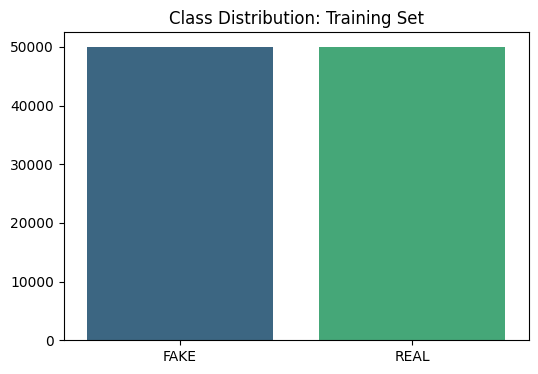

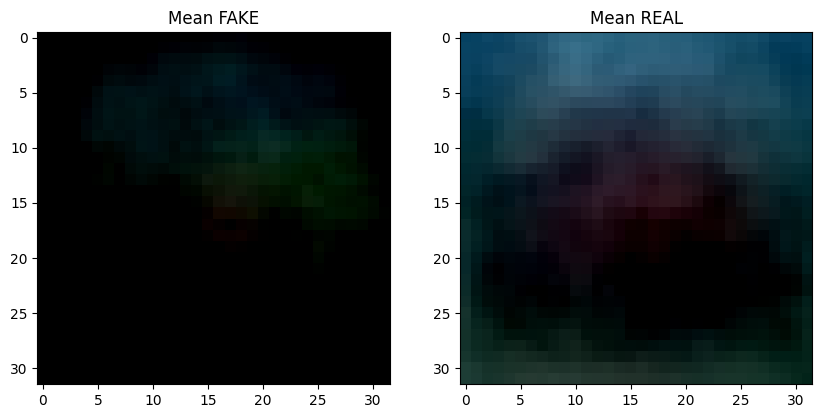

In [11]:
# 1. Distribution Plot
def plot_distribution(dataset, title):
    counts = {dataset.classes[i]: 0 for i in range(len(dataset.classes))}
    for _, label in dataset.samples:
        counts[dataset.classes[label]] += 1
    plt.figure(figsize=(6, 4))
    sns.barplot(x=list(counts.keys()), y=list(counts.values()), palette="viridis")
    plt.title(f"Class Distribution: {title}")
    plt.show()

plot_distribution(full_train_data, "Training Set")

# 2. Mean Image Analysis
def show_mean_images(dataset):
    def get_mean_img(class_idx):
        indices = [i for i, (_, label) in enumerate(dataset.samples) if label == class_idx]
        subset = np.random.choice(indices, 500)
        imgs = [dataset[idx][0].numpy() for idx in subset]
        return np.mean(imgs, axis=0)

    mean_fake = get_mean_img(0)
    mean_real = get_mean_img(1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
    ax1.imshow(np.transpose(mean_fake, (1, 2, 0)).clip(0, 1))
    ax1.set_title("Mean FAKE")
    ax2.imshow(np.transpose(mean_real, (1, 2, 0)).clip(0, 1))
    ax2.set_title("Mean REAL")
    plt.show()

show_mean_images(full_train_data)

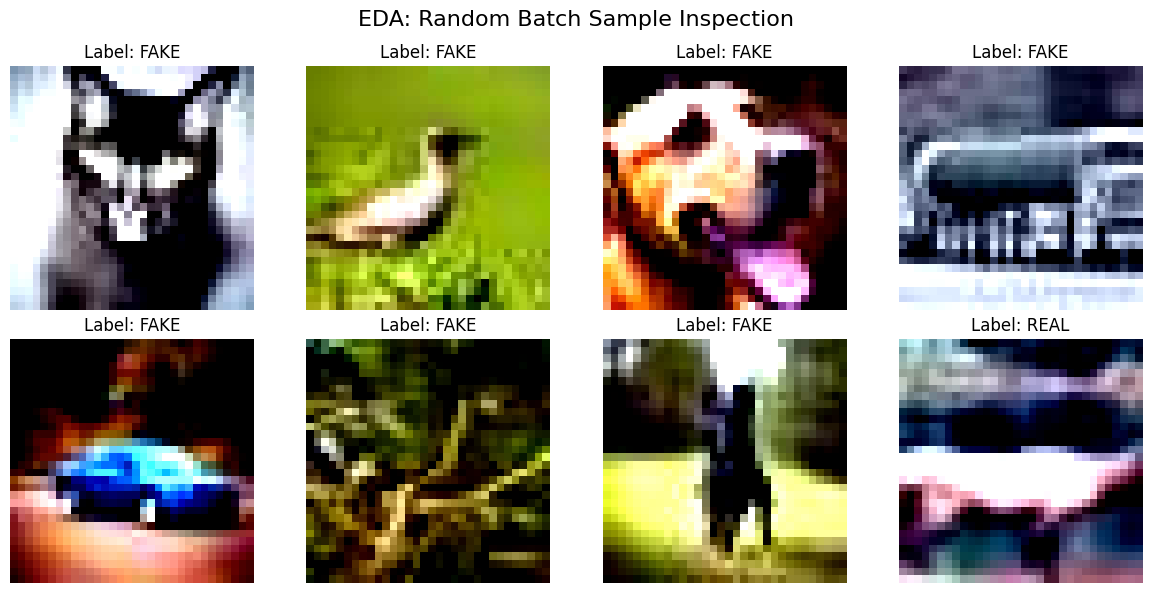

In [12]:
# Function to visualise a random batch from the loader
def show_batch_samples(loader):
    images, labels = next(iter(loader))
    plt.figure(figsize=(12, 6))

    # Show first 8 images in the batch
    for i in range(8):
        plt.subplot(2, 4, i+1)
        # Denormalise for viewing
        img = images[i].permute(1, 2, 0) * 0.5 + 0.5
        plt.imshow(img.clamp(0, 1))
        plt.title(f"Label: {classes[labels[i]]}")
        plt.axis('off')

    plt.suptitle("EDA: Random Batch Sample Inspection", fontsize=16)
    plt.tight_layout()
    plt.show()

show_batch_samples(train_loader)

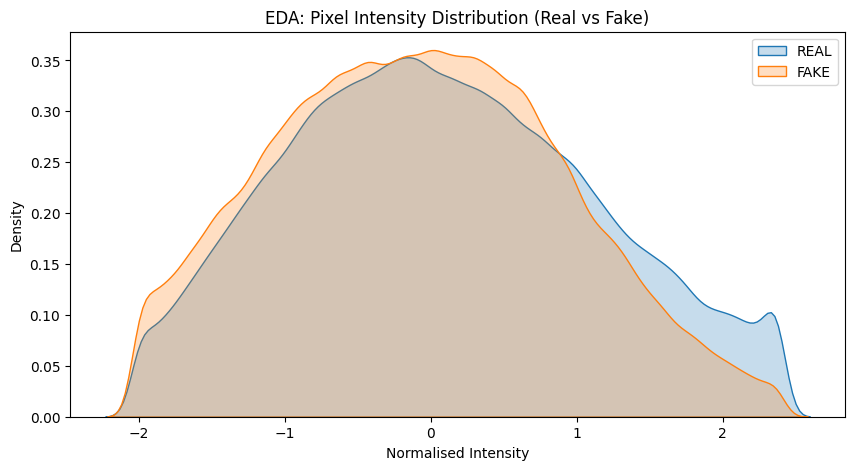

In [13]:
import numpy as np

def plot_intensity_distribution(dataset):
    real_indices = [i for i, (_, label) in enumerate(dataset.samples) if label == dataset.class_to_idx['REAL']]
    fake_indices = [i for i, (_, label) in enumerate(dataset.samples) if label == dataset.class_to_idx['FAKE']]

    # Sample 1000 images from each to save time
    real_sample = np.random.choice(real_indices, 1000)
    fake_sample = np.random.choice(fake_indices, 1000)

    def get_intensities(indices):
        intensities = []
        for idx in indices:
            img, _ = dataset[idx]
            # Convert to grayscale for simple intensity check
            gray = 0.2989 * img[0] + 0.5870 * img[1] + 0.1140 * img[2]
            intensities.extend(gray.flatten().numpy())
        return intensities

    plt.figure(figsize=(10, 5))
    sns.kdeplot(get_intensities(real_sample), label="REAL", fill=True)
    sns.kdeplot(get_intensities(fake_sample), label="FAKE", fill=True)
    plt.title("EDA: Pixel Intensity Distribution (Real vs Fake)")
    plt.xlabel("Normalised Intensity")
    plt.legend()
    plt.show()

plot_intensity_distribution(full_train_data)

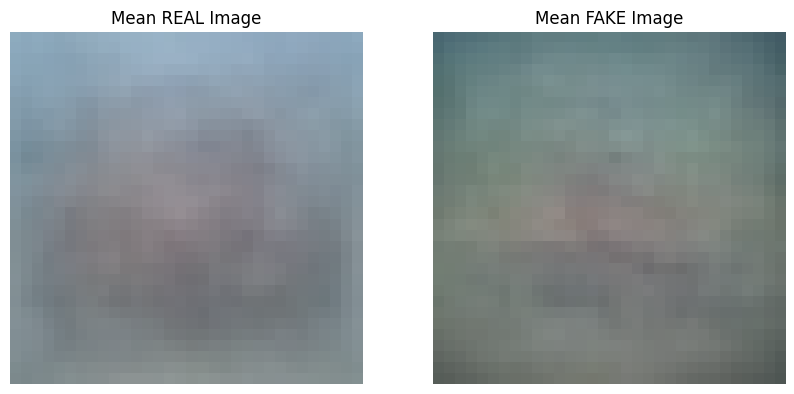

In [14]:
def show_mean_images(dataset):
    def get_mean_img(class_name):
        indices = [i for i, (_, label) in enumerate(dataset.samples) if label == dataset.class_to_idx[class_name]]
        subset = np.random.choice(indices, 500)
        imgs = []
        for idx in subset:
            img, _ = dataset[idx]
            imgs.append(img.numpy())
        return np.mean(imgs, axis=0)

    mean_real = get_mean_img('REAL')
    mean_fake = get_mean_img('FAKE')

    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(np.transpose(mean_real * 0.5 + 0.5, (1, 2, 0)))
    plt.title("Mean REAL Image")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(np.transpose(mean_fake * 0.5 + 0.5, (1, 2, 0)))
    plt.title("Mean FAKE Image")
    plt.axis('off')
    plt.show()

show_mean_images(full_train_data)

# Building Model

In [15]:
# Section 3 Configuration
LR = 0.001
EPOCHS = 10
NUM_CLASSES = 2

# Proposed Model: Pre-trained ResNet-18
model = models.resnet18(weights='DEFAULT')
model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LR)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 194MB/s]


# Epoch Training

In [16]:
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

for epoch in range(EPOCHS):
    # Training Phase
    model.train()
    t_running_loss, t_correct, t_total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        t_running_loss += loss.item()
        _, predicted = outputs.max(1)
        t_total += labels.size(0)
        t_correct += predicted.eq(labels).sum().item()

    # Validation Phase
    model.eval()
    v_running_loss, v_correct, v_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            v_running_loss += loss.item()
            _, predicted = outputs.max(1)
            v_total += labels.size(0)
            v_correct += predicted.eq(labels).sum().item()

    # Metrics Calculation
    train_loss, train_acc = t_running_loss/len(train_loader), 100.*t_correct/t_total
    val_loss, val_acc = v_running_loss/len(val_loader), 100.*v_correct/v_total

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(f"Epoch: {epoch} | Train Acc: {train_acc:.2f}% | Val Acc: {val_acc:.2f}%")

Epoch: 0 | Train Acc: 91.66% | Val Acc: 93.66%
Epoch: 1 | Train Acc: 94.46% | Val Acc: 94.61%
Epoch: 2 | Train Acc: 94.93% | Val Acc: 95.08%
Epoch: 3 | Train Acc: 95.77% | Val Acc: 96.18%
Epoch: 4 | Train Acc: 96.32% | Val Acc: 96.04%
Epoch: 5 | Train Acc: 96.72% | Val Acc: 96.00%
Epoch: 6 | Train Acc: 97.10% | Val Acc: 96.28%
Epoch: 7 | Train Acc: 97.43% | Val Acc: 96.87%
Epoch: 8 | Train Acc: 97.76% | Val Acc: 96.50%
Epoch: 9 | Train Acc: 97.99% | Val Acc: 96.47%


## Analysis:

Analysis:
Look at Epoch 9:
Train Acc: 97.99%
Val Acc: 96.47%

The fact that the Training Accuracy is higher than Validation Accuracy is a classic sign of slight overfitting.

Test a model from scratch to see if the accuracy is the same:

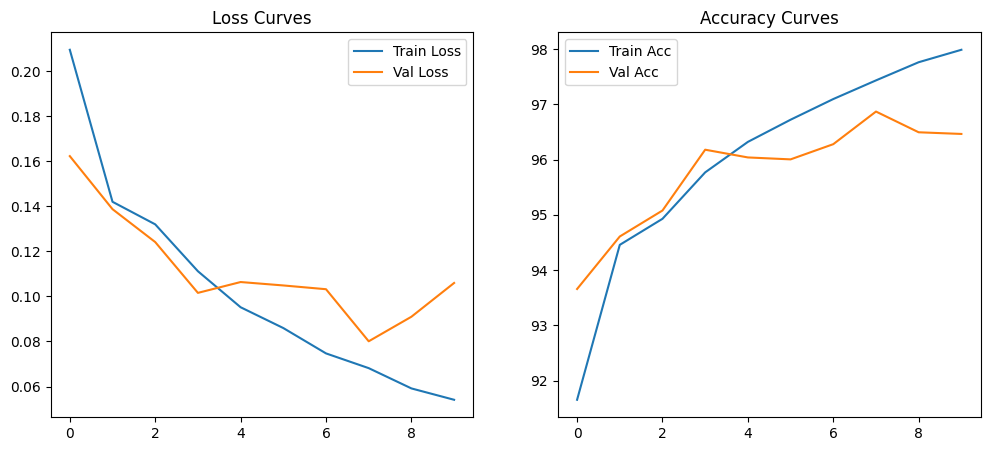

In [17]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Val Loss")
plt.title("Loss Curves")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history["train_acc"], label="Train Acc")
plt.plot(history["val_acc"], label="Val Acc")
plt.title("Accuracy Curves")
plt.legend()
plt.show()

# Comparison to Untrained Model:

In [18]:
# Create a second model without pre-trained weights (Lab 06 logic)
model_scratch = models.resnet18(weights=None)

# Same modification to the final layer as before
num_ftrs = model_scratch.fc.in_features
model_scratch.fc = nn.Linear(num_ftrs, 2)

model_scratch = model_scratch.to(device)

# New optimizer for this specific model
optimizer_scratch = optim.Adam(model_scratch.parameters(), lr=0.001)

In [19]:
def train_scratch_one_epoch():
    model_scratch.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer_scratch.zero_grad()
        outputs = model_scratch(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_scratch.step()

        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        running_loss += loss.item()

    return running_loss/len(train_loader), 100.*correct/total

# Run for 1 Epoch
scratch_loss, scratch_acc = train_scratch_one_epoch()
print(f"Scratch Model (1 Epoch) Acc: {scratch_acc:.2f}%")

Scratch Model (1 Epoch) Acc: 87.42%


## Analysis:

# Plots for Analysis

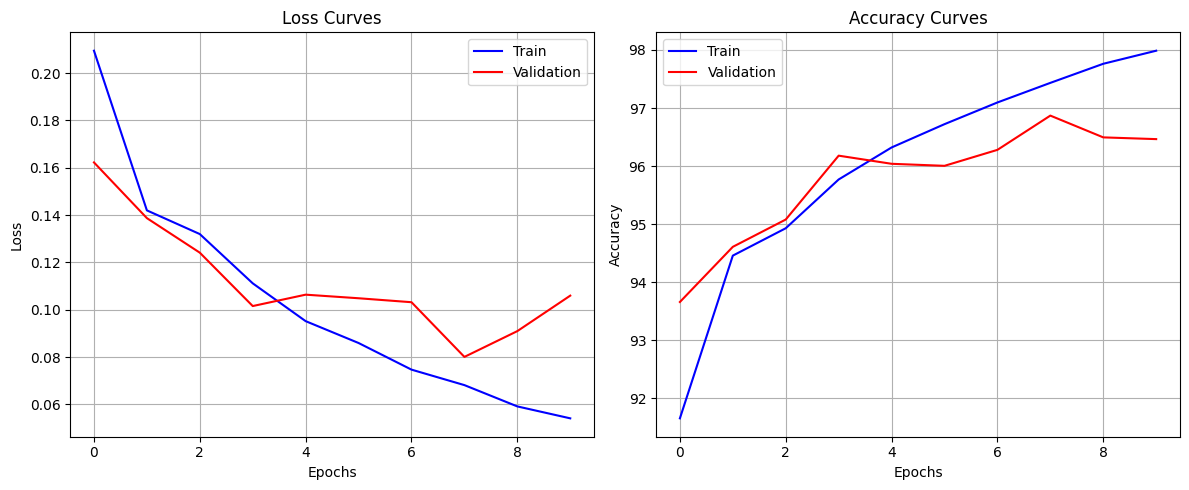

In [20]:
import matplotlib.pyplot as plt

# Plotting style matches Lab 08 helper code
plt.figure(figsize=(12, 5))

# Plot Loss Curve (Quantitative)
plt.subplot(1, 2, 1)
plt.plot(history["train_loss"], label="Train", color="blue")
plt.plot(history["val_loss"], label="Validation", color="red")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss Curves")
plt.legend()
plt.grid(True)

# Plot Accuracy Curve (Quantitative)
plt.subplot(1, 2, 2)
plt.plot(history["train_acc"], label="Train", color="blue")
plt.plot(history["val_acc"], label="Validation", color="red")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Accuracy Curves")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

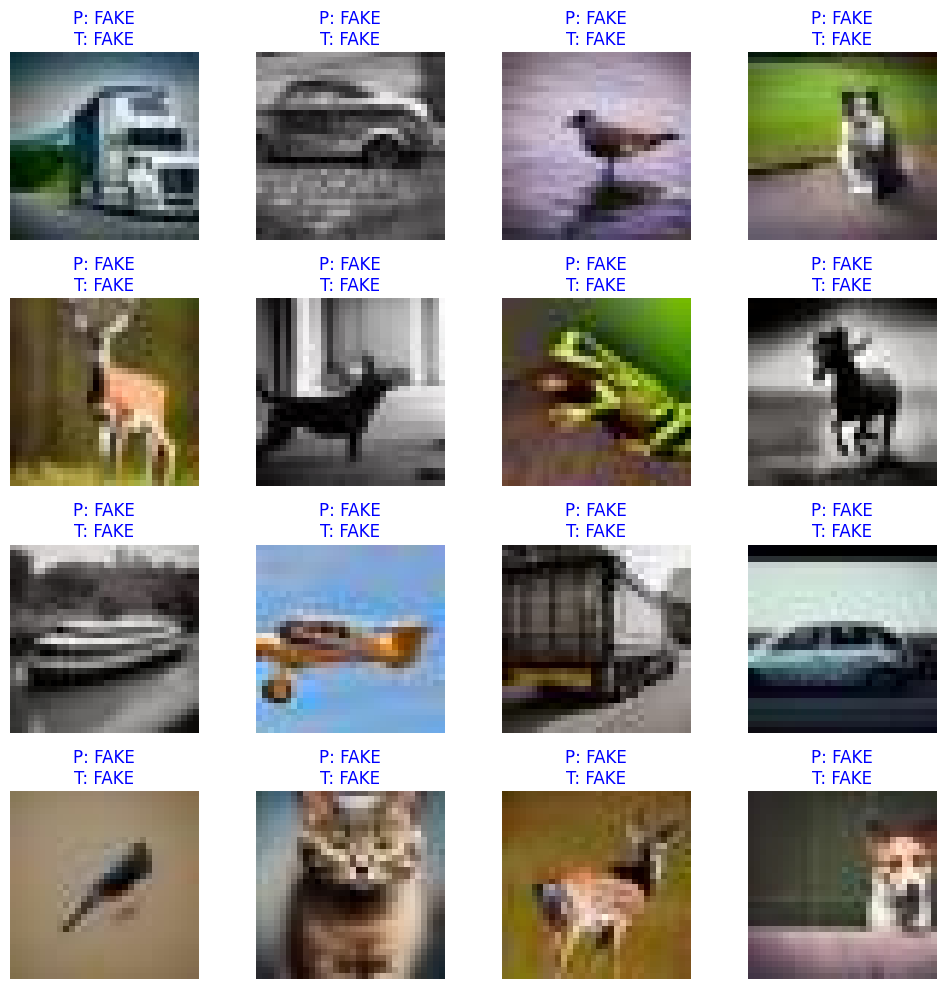

In [22]:
# Function to denormalize for display
def denormalize(tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).reshape(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).reshape(3, 1, 1)
    return tensor * std + mean

def verify_images():
    images, labels = next(iter(test_loader))
    images, labels = images.to(device), labels.to(device)
    model.eval()
    with torch.no_grad():
        outputs = model(images)
        preds = outputs.argmax(dim=1)

    fig, axes = plt.subplots(4, 4, figsize=(10, 10))
    for idx, ax in enumerate(axes.flat):
        img = denormalize(images[idx].cpu())
        ax.imshow(img.permute(1, 2, 0).clamp(0, 1))
        is_correct = preds[idx] == labels[idx]
        ax.set_title(f"P: {classes[preds[idx]]}\nT: {classes[labels[idx]]}", color='blue' if is_correct else 'red')
        ax.axis('off')
    plt.tight_layout()
    plt.show()

verify_images()

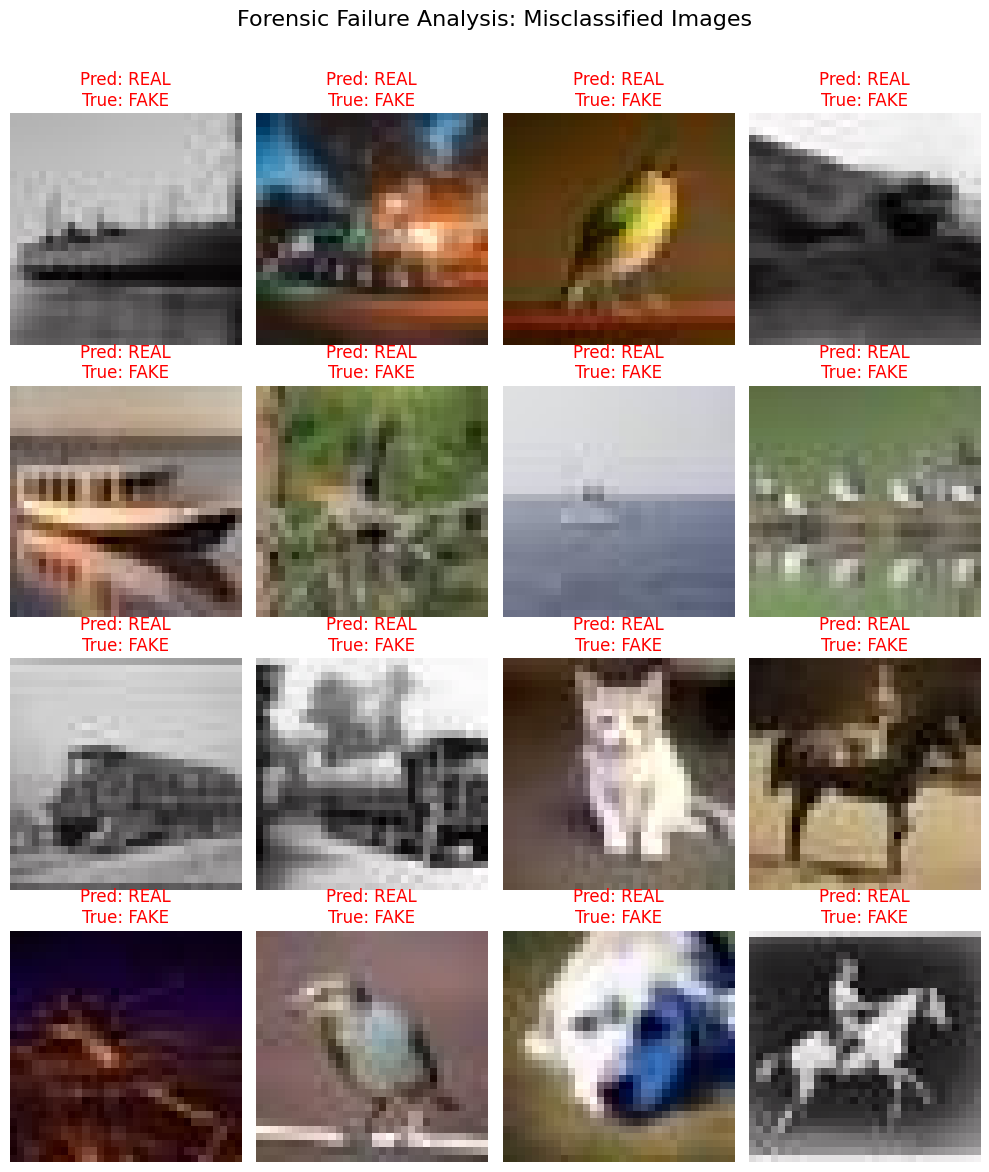

In [23]:
def show_failures():
    model.eval()
    failed_images = []
    failed_preds = []
    failed_labels = []

    # Need to check a few batches to find 16 errors
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            preds = outputs.argmax(dim=1)

            # Find indices where prediction != label
            mask = preds != labels
            if mask.any():
                failed_images.append(images[mask].cpu())
                failed_preds.append(preds[mask].cpu())
                failed_labels.append(labels[mask].cpu())

            # Stop once enough for a 4x4 grid
            if sum([x.size(0) for x in failed_images]) >= 16:
                break

    # Concatenate and take first 16
    failed_images = torch.cat(failed_images)[:16]
    failed_preds = torch.cat(failed_preds)[:16]
    failed_labels = torch.cat(failed_labels)[:16]

    # Plotting
    fig, axes = plt.subplots(4, 4, figsize=(10, 12))
    fig.suptitle("Forensic Failure Analysis: Misclassified Images", fontsize=16)

    for idx, ax in enumerate(axes.flat):
        img = denormalize(failed_images[idx])
        ax.imshow(img.permute(1, 2, 0).clamp(0, 1))

        # In a failure analysis, these will all be RED
        ax.set_title(f"Pred: {classes[failed_preds[idx]]}\nTrue: {classes[failed_labels[idx]]}", color='red')
        ax.axis('off')

    plt.tight_layout()
    plt.subplots_adjust(top=0.9)
    plt.show()

show_failures()

# Saliency Test
See where the model is focusing on in each part

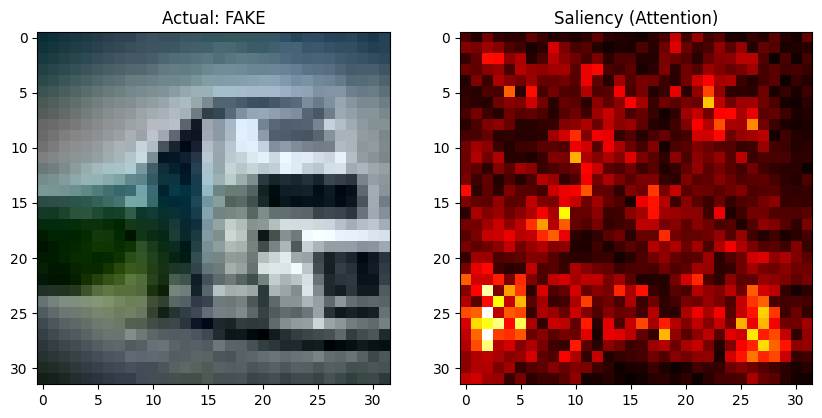

In [24]:
def generate_saliency(img_idx):
    model.eval()
    img, label = test_data[img_idx]
    img_tensor = img.unsqueeze(0).to(device)
    img_tensor.requires_grad_()

    output = model(img_tensor)
    output[0, output.argmax()].backward()

    saliency, _ = torch.max(torch.abs(img_tensor.grad.data[0]), dim=0)

    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    view_img = denormalize(img).permute(1, 2, 0).numpy()
    plt.imshow(view_img.clip(0, 1))
    plt.title(f"Actual: {classes[label]}")
    plt.subplot(1, 2, 2)
    plt.imshow(saliency.cpu(), cmap='hot')
    plt.title("Saliency (Attention)")
    plt.show()

generate_saliency(0)
# Test it on FAKE images from the test set
# generate_saliency_map(sample_fake_path)

In [25]:
# Get a path for one REAL and one FAKE image
test_real_dir = os.path.join(test_dir, 'REAL')
test_fake_dir = os.path.join(test_dir, 'FAKE')

# Select the first image in each folder
sample_real = os.path.join(test_real_dir, os.listdir(test_real_dir)[20])
sample_fake = os.path.join(test_fake_dir, os.listdir(test_fake_dir)[20])

Analysing a FAKE Image 


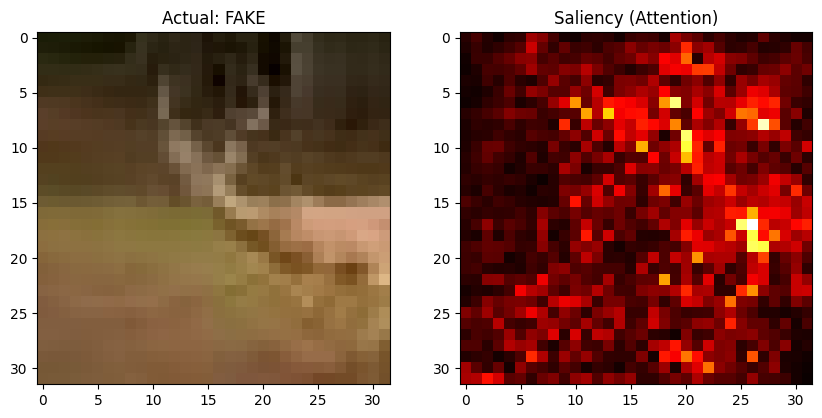

Analysing a REAL Image 


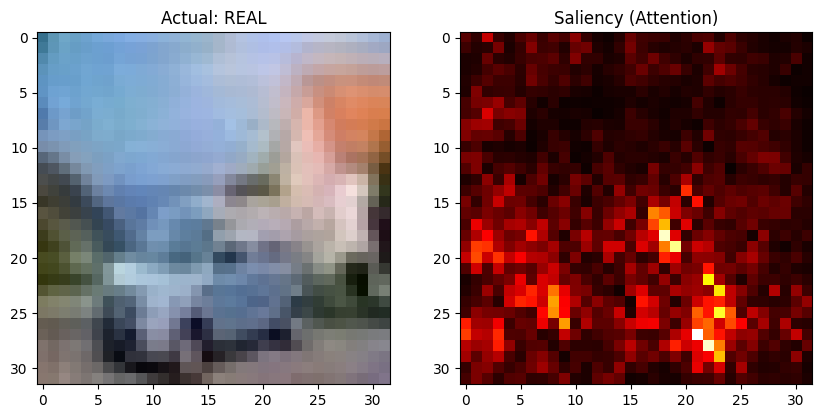

In [29]:
def get_index_from_path(image_path, dataset):
    for i, (path, _) in enumerate(dataset.samples):
        if path == image_path:
            return i
    return -1 # Not found

print("Analysing a FAKE Image ")
fake_idx = get_index_from_path(sample_fake, test_data)
if fake_idx != -1:
    generate_saliency(fake_idx)
else:
    print(f"Image path not found in test_data: {sample_fake}")

print("Analysing a REAL Image ")
real_idx = get_index_from_path(sample_real, test_data)
if real_idx != -1:
    generate_saliency(real_idx)
else:
    print(f"Image path not found in test_data: {sample_real}")

log

In [30]:
# BASELINE: Custom CNN (Mimicking Bird & Lotfi's 2024 Baseline)
class BaselineCNN(nn.Module):
    def __init__(self):
        super(BaselineCNN, self).__init__()
        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 512), nn.ReLU(),
            nn.Linear(512, 2)
        )
    def forward(self, x):
        return self.conv_layers(x)

baseline_model = BaselineCNN().to(device)
# (Runs for few epochs and record the accuracy

In [31]:
# 1. Initialise the Baseline Model
baseline_model = BaselineCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(baseline_model.parameters(), lr=0.001)

# 2. Training Loop for Baseline
baseline_epochs = 4
# 'train_loss' to the dictionary to track data
baseline_history = {'train_acc': [], 'train_loss': []}

print("Starting Baseline Training (SOTA Reproduction)...")

for epoch in range(baseline_epochs):
    baseline_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = baseline_model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # Track the loss for this batch
        running_loss += loss.item()

        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    # Calculate average loss for the epoch and save it
    epoch_loss = running_loss / len(train_loader)
    baseline_history['train_loss'].append(epoch_loss)

    train_acc = 100 * correct / total
    baseline_history['train_acc'].append(train_acc)
    print(f"Epoch {epoch+1}/{baseline_epochs} - Loss: {epoch_loss:.4f}, Acc: {train_acc:.2f}%")

print("Baseline Training Complete.")

Starting Baseline Training (SOTA Reproduction)...
Epoch 1/4 - Loss: 0.2739, Acc: 88.03%
Epoch 2/4 - Loss: 0.1722, Acc: 93.16%
Epoch 3/4 - Loss: 0.1465, Acc: 94.31%
Epoch 4/4 - Loss: 0.1293, Acc: 95.01%
Baseline Training Complete.


Comparison to Trained Model using ResNet

ResNet Epoch 9:
Train Acc: 97.99%
Val Acc: 96.47%

SOTA Epoch 4 (Saving Computational Time)
Train Acc: 95.01%

Even Epoch 3 on ResNet performs better than 4th Epoch on SOTA, with Epoch: 3 returning Train Acc: 95.77%.

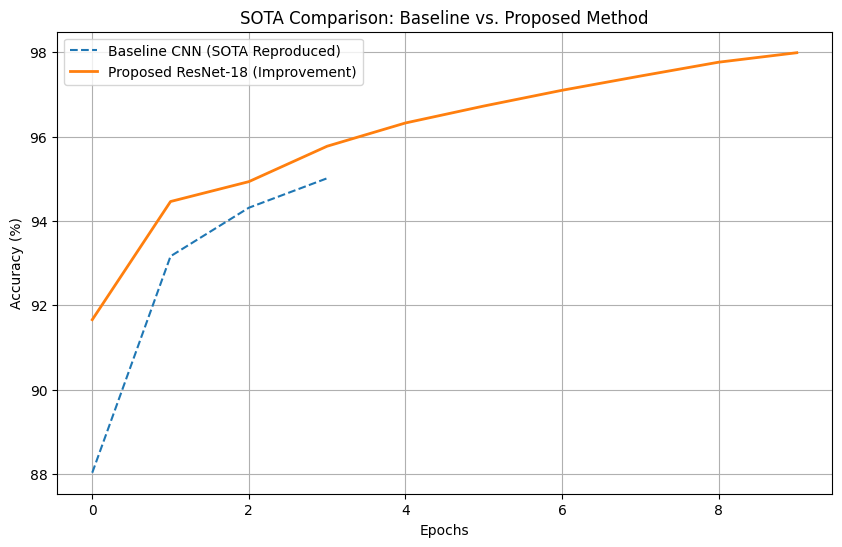

In [33]:
plt.figure(figsize=(10, 6))
plt.plot(baseline_history['train_acc'], label='Baseline CNN (SOTA Reproduced)', linestyle='--')
plt.plot(history['train_acc'], label='Proposed ResNet-18 (Improvement)', linewidth=2)
plt.title("SOTA Comparison: Baseline vs. Proposed Method")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)
plt.show()

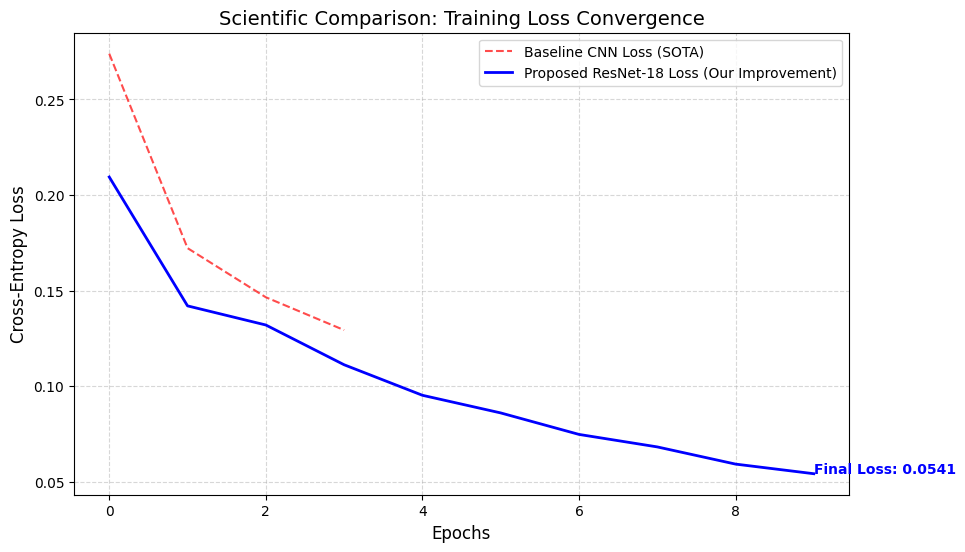

In [34]:
plt.figure(figsize=(10, 6))

# 1. Plot the Baseline Loss
plt.plot(baseline_history['train_loss'], label='Baseline CNN Loss (SOTA)', color='red', linestyle='--', alpha=0.7)

# 2. Plot Improved ResNet Loss
plt.plot(history['train_loss'], label='Proposed ResNet-18 Loss (Our Improvement)', color='blue', linewidth=2)

plt.title("Scientific Comparison: Training Loss Convergence", fontsize=14)
plt.xlabel("Epochs", fontsize=12)
plt.ylabel("Cross-Entropy Loss", fontsize=12)
plt.legend()
plt.grid(True, which='both', linestyle='--', alpha=0.5)

plt.text(len(history['train_loss'])-1, history['train_loss'][-1],
         f"Final Loss: {history['train_loss'][-1]:.4f}", color='blue', fontweight='bold')

plt.show()

Text(0.5, 1.0, 'Head-to-Head Performance (First 4 Epochs)')

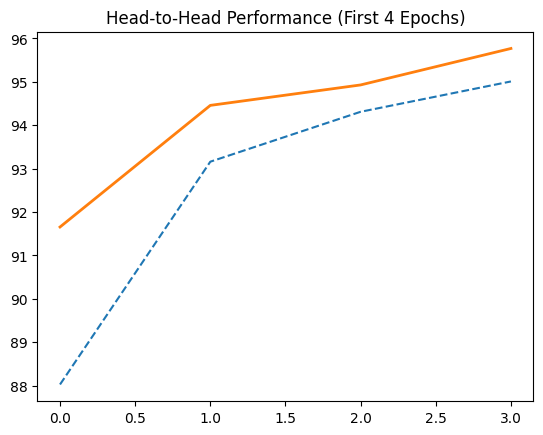

In [35]:
# Head-to-Head Comparison (First 4 Epochs)
plt.plot(baseline_history['train_acc'][:4], label='Baseline (SOTA)', linestyle='--')
plt.plot(history['train_acc'][:4], label='Proposed ResNet-18', linewidth=2)
plt.title("Head-to-Head Performance (First 4 Epochs)")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 24.7 MB/s eta 0:00:00


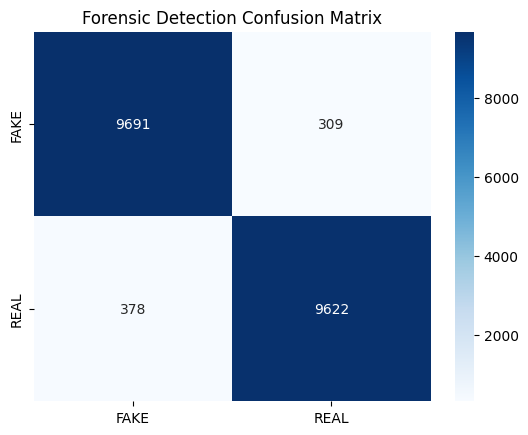

In [21]:
!pip install torchmetrics
from torchmetrics import ConfusionMatrix

test_confusion_matrix = ConfusionMatrix(task="multiclass", num_classes=2).to(device)
model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1)
        test_confusion_matrix.update(preds, labels)

sns.heatmap(test_confusion_matrix.compute().cpu(), annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.title("Forensic Detection Confusion Matrix")
plt.show()

In [42]:
from sklearn.metrics import classification_report, accuracy_score

# Generate Predictions
model.eval()
y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1)
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

# Calculate individual scores for report text
test_accuracy = accuracy_score(y_true, y_pred)

# Print the full Forensic Classification Report
# This provides Precision, Recall, and F1-Score for BOTH classes
print("Forensic Performance Analysis")
print(classification_report(y_true, y_pred, target_names=classes, digits=4))

Forensic Performance Analysis
              precision    recall  f1-score   support

        FAKE     0.9625    0.9691    0.9658     10000
        REAL     0.9689    0.9622    0.9655     10000

    accuracy                         0.9657     20000
   macro avg     0.9657    0.9657    0.9656     20000
weighted avg     0.9657    0.9657    0.9656     20000



In [37]:
from torchsummary import summary

# Shows the architecture and the exact number of parameters
# (3, 32, 32) matches the CIFAKE image dimensions
summary(model, input_size=(3, 32, 32))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 16, 16]           9,408
       BatchNorm2d-2           [-1, 64, 16, 16]             128
              ReLU-3           [-1, 64, 16, 16]               0
         MaxPool2d-4             [-1, 64, 8, 8]               0
            Conv2d-5             [-1, 64, 8, 8]          36,864
       BatchNorm2d-6             [-1, 64, 8, 8]             128
              ReLU-7             [-1, 64, 8, 8]               0
            Conv2d-8             [-1, 64, 8, 8]          36,864
       BatchNorm2d-9             [-1, 64, 8, 8]             128
             ReLU-10             [-1, 64, 8, 8]               0
       BasicBlock-11             [-1, 64, 8, 8]               0
           Conv2d-12             [-1, 64, 8, 8]          36,864
      BatchNorm2d-13             [-1, 64, 8, 8]             128
             ReLU-14             [-1, 6

# Gradio Application

In [38]:
# Save the model weights
model_path = "resnet18_cifake.pth"
torch.save(model.state_dict(), model_path)
print(f"Model saved to {model_path}")

Model saved to resnet18_cifake.pth


In [41]:
# Final Cell: Deployment & User Interface (Lab 10 Alignment)
import warnings
warnings.filterwarnings('ignore')
import gradio as gr

# Load the saved model for the app
app_model = models.resnet18()
app_model.fc = nn.Linear(app_model.fc.in_features, 2)
app_model.load_state_dict(torch.load("resnet18_cifake.pth", map_location=device))
app_model.to(device)
app_model.eval()

def predict_image(img):
    # Uses the same evaluation transform as earlier
    preprocess = transforms.Compose([
        transforms.Resize((32, 32)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
    img_tensor = preprocess(img).unsqueeze(0).to(device)
    with torch.no_grad():
        outputs = app_model(img_tensor)
        probs = torch.nn.functional.softmax(outputs[0], dim=0)
        return {classes[i]: float(probs[i]) for i in range(2)}

# Build the Interface
interface = gr.Interface(
    fn=predict_image,
    inputs=gr.Image(type="pil"),
    outputs=gr.Label(num_top_classes=2),
    title="AI Forensic Detector",
    description="Application developed for 6G7V0024. Submit an image to detect AI-generated synthetic content."
)

# inline=True ensures the app is captured in the notebook's static output
interface.launch(share=True, inline=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://03c187a9bb25ad6f8c.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
